# 26 — Final Results & Case Studies
## Thesis-ready interpretation of the frozen masked temporal anomaly model

This notebook **does not train or tune any model**.

The model and primary candidate rule are already frozen:

- architecture: `T_FIRE`;
- temporal context: 7 days;
- five independently trained seeds: 11, 22, 33, 44, 55;
- final anomaly score: median within-day reconstruction-error rank across five seeds;
- robust candidate rule: actual hotspot AND median rank ≥ 0.80 AND at least 4/5 seeds rank ≥ 0.80.

The purpose of this notebook is to create final evidence for the thesis:

1. candidate enrichment in Emerging-3 vs Persistent events;
2. cross-seed stability;
3. relationship to the previous history anomaly;
4. spatial/temporal concentration summaries;
5. balanced case studies from distinct grid cells;
6. thesis-ready figures and tables.

### Important interpretation

A candidate is a **contextual satellite hotspot anomaly**:
its current fire state is difficult to reconstruct from the learned preceding temporal fire context.

It is **not** a label of human ignition, intentional burning, illegality, or natural ignition.

In [12]:
# 1. Imports

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import fisher_exact

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 320)

In [13]:
# 2. Resolve project root and NB25 exports

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    export_dir = (
        root
        / "model_results"
        / "final_masked_temporal_anomaly"
        / "t2"
        / "exports"
    )

    required = [
        export_dir
        / "august_hotspot_candidate_analysis.csv",
        export_dir
        / "august_final_robust_anomaly_candidates.csv",
        export_dir
        / "candidate_reconstruction_expectation.csv",
        export_dir
        / "hotspot_seed_agreement_distribution.csv",
    ]

    data_path = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )

    if (
        all(p.exists() for p in required)
        and data_path.exists()
    ):
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the NB25 exports and regional dataset. "
        "Run NB25 successfully first."
    )

NB25_EXPORT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "final_masked_temporal_anomaly"
    / "t2"
    / "exports"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "final_results_case_studies"
    / "t2"
)

EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"

EXPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("RESULT_DIR:", RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
RESULT_DIR: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2


In [14]:
# 3. Load frozen NB25 results

analysis = pd.read_csv(
    NB25_EXPORT_DIR
    / "august_hotspot_candidate_analysis.csv",
    parse_dates=["event_date"],
)

candidates = pd.read_csv(
    NB25_EXPORT_DIR
    / "august_final_robust_anomaly_candidates.csv",
    parse_dates=["date"],
)

expectation = pd.read_csv(
    NB25_EXPORT_DIR
    / "candidate_reconstruction_expectation.csv",
    parse_dates=["date"],
)

agreement = pd.read_csv(
    NB25_EXPORT_DIR
    / "hotspot_seed_agreement_distribution.csv"
)

sensitivity = pd.read_csv(
    NB25_EXPORT_DIR
    / "candidate_threshold_sensitivity.csv"
)

raw = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

print("Labeled/merged hotspot rows:", len(analysis))
print("Frozen robust candidates:", len(candidates))
print("Expectation rows:", len(expectation))

Labeled/merged hotspot rows: 2106
Frozen robust candidates: 620
Expectation rows: 620


# PART A — Final candidate enrichment

The anomaly model was trained without Emerging/Persistent labels.

Therefore Emerging-3 vs Persistent is used here as a **post-hoc behavioral validation**.

We ask:

> How often does each group satisfy the frozen robust-anomaly rule?

The most useful effect size is the **candidate-rate ratio**, not only a p-value.

In [15]:
# 4. Candidate rates by research group

known = analysis[
    analysis[
        "research_group"
    ].isin(
        [
            "Emerging-3",
            "Persistent",
        ]
    )
].copy()

group_counts = (
    known
    .groupby(
        "research_group"
    )
    .agg(
        hotspot_events=(
            "cell_id",
            "size",
        ),
        robust_candidates=(
            "robust_anomaly_candidate",
            "sum",
        ),
    )
    .reset_index()
)

group_counts[
    "candidate_rate"
] = (
    group_counts[
        "robust_candidates"
    ]
    / group_counts[
        "hotspot_events"
    ]
)

display(group_counts)

,research_group,hotspot_events,robust_candidates,candidate_rate
0,Emerging-3,217,118,0.543779
1,Persistent,1849,476,0.257436


In [16]:
# 5. Candidate-rate effect size

def get_group_value(group, col):
    return float(
        group_counts.loc[
            group_counts[
                "research_group"
            ].eq(group),
            col,
        ].iloc[0]
    )

em_n = int(
    get_group_value(
        "Emerging-3",
        "hotspot_events",
    )
)

em_c = int(
    get_group_value(
        "Emerging-3",
        "robust_candidates",
    )
)

pe_n = int(
    get_group_value(
        "Persistent",
        "hotspot_events",
    )
)

pe_c = int(
    get_group_value(
        "Persistent",
        "robust_candidates",
    )
)

em_rate = em_c / em_n
pe_rate = pe_c / pe_n

risk_ratio = (
    em_rate / pe_rate
)

risk_difference = (
    em_rate - pe_rate
)

# Katz log CI for risk ratio.
rr_se = np.sqrt(
    (1 / em_c)
    - (1 / em_n)
    + (1 / pe_c)
    - (1 / pe_n)
)

rr_ci_low = np.exp(
    np.log(risk_ratio)
    - 1.96 * rr_se
)

rr_ci_high = np.exp(
    np.log(risk_ratio)
    + 1.96 * rr_se
)

table = np.array([
    [
        em_c,
        em_n - em_c,
    ],
    [
        pe_c,
        pe_n - pe_c,
    ],
])

odds_ratio, fisher_p = fisher_exact(
    table,
    alternative="two-sided",
)

effect_summary = pd.DataFrame({
    "metric": [
        "Emerging candidate rate",
        "Persistent candidate rate",
        "Risk ratio Emerging/Persistent",
        "Risk difference",
        "Risk-ratio 95% CI lower",
        "Risk-ratio 95% CI upper",
        "Fisher exact p-value",
    ],
    "value": [
        em_rate,
        pe_rate,
        risk_ratio,
        risk_difference,
        rr_ci_low,
        rr_ci_high,
        fisher_p,
    ],
})

display(effect_summary)

,metric,value
0,Emerging candidate rate,5.437788e-01
1,Persistent candidate rate,2.574365e-01
2,Risk ratio Emerging/Persistent,2.112284e+00
3,Risk difference,2.863423e-01
4,Risk-ratio 95% CI lower,1.828305e+00
5,Risk-ratio 95% CI upper,2.440370e+00
6,Fisher exact p-value,4.892823e-17


In [17]:
# 6. Candidate composition enrichment

known_total = len(known)

known_candidates = known[
    known[
        "robust_anomaly_candidate"
    ]
]

baseline_emerging_share = (
    (
        known[
            "research_group"
        ]
        == "Emerging-3"
    ).mean()
)

candidate_emerging_share = (
    (
        known_candidates[
            "research_group"
        ]
        == "Emerging-3"
    ).mean()
)

composition_enrichment = (
    candidate_emerging_share
    / baseline_emerging_share
)

composition_summary = pd.DataFrame({
    "metric": [
        "Emerging share among all labeled hotspots",
        "Emerging share among robust candidates",
        "Emerging composition enrichment",
    ],
    "value": [
        baseline_emerging_share,
        candidate_emerging_share,
        composition_enrichment,
    ],
})

display(composition_summary)

,metric,value
0,Emerging share among all labeled hotspots,0.105034
1,Emerging share among robust candidates,0.198653
2,Emerging composition enrichment,1.891325


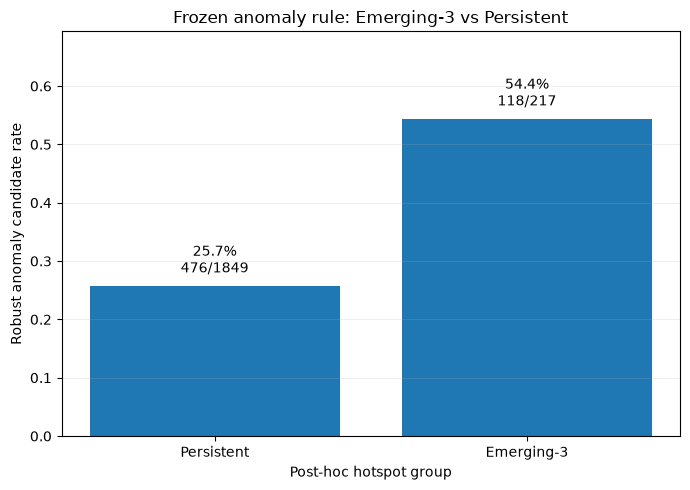

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2\figures\01_candidate_rate_by_group.png


In [18]:
# 7. Thesis-ready candidate-rate figure

plot_df = (
    group_counts
    .set_index(
        "research_group"
    )
    .loc[
        [
            "Persistent",
            "Emerging-3",
        ]
    ]
    .reset_index()
)

fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.bar(
    plot_df[
        "research_group"
    ],
    plot_df[
        "candidate_rate"
    ],
)

for i, row in plot_df.iterrows():
    ax.text(
        i,
        row[
            "candidate_rate"
        ] + 0.015,
        (
            f"{row['candidate_rate']:.1%}\n"
            f"{int(row['robust_candidates'])}/"
            f"{int(row['hotspot_events'])}"
        ),
        ha="center",
        va="bottom",
    )

ax.set_ylim(
    0,
    min(
        1.0,
        max(
            plot_df[
                "candidate_rate"
            ]
        ) + 0.15,
    ),
)

ax.set_ylabel(
    "Robust anomaly candidate rate"
)

ax.set_xlabel(
    "Post-hoc hotspot group"
)

ax.set_title(
    "Frozen anomaly rule: Emerging-3 vs Persistent"
)

ax.grid(
    axis="y",
    alpha=0.2,
)

plt.tight_layout()

path = (
    FIGURE_DIR
    / "01_candidate_rate_by_group.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path)

# PART B — Cross-seed stability

The frozen rule requires at least 4 of 5 seeds to rank an event ≥ 0.80.

This section shows how much agreement exists across independently initialized models.

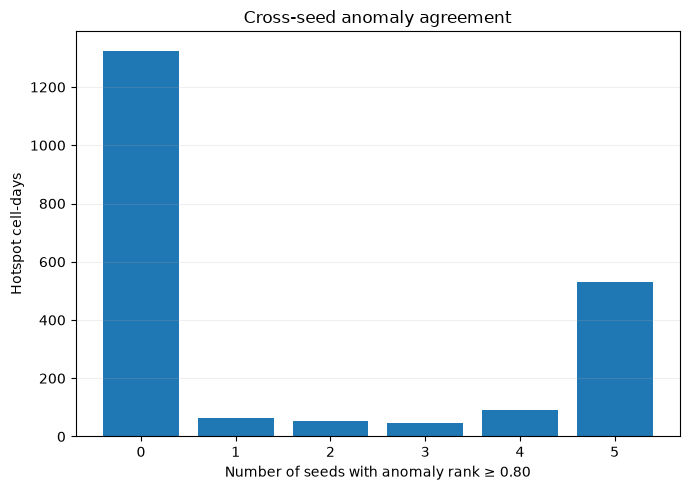

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2\figures\02_seed_agreement_distribution.png


In [19]:
# 8. Seed-agreement figure

agreement_plot = (
    agreement
    .sort_values(
        "high_seed_count"
    )
)

fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.bar(
    agreement_plot[
        "high_seed_count"
    ].astype(str),
    agreement_plot[
        "hotspot_events"
    ],
)

ax.set_xlabel(
    "Number of seeds with anomaly rank ≥ 0.80"
)

ax.set_ylabel(
    "Hotspot cell-days"
)

ax.set_title(
    "Cross-seed anomaly agreement"
)

ax.grid(
    axis="y",
    alpha=0.2,
)

plt.tight_layout()

path = (
    FIGURE_DIR
    / "02_seed_agreement_distribution.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path)

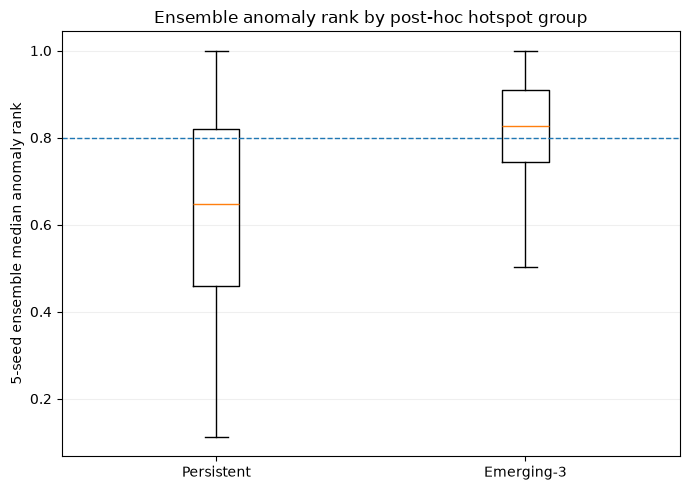

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2\figures\03_ensemble_rank_by_group.png


In [20]:
# 9. Ensemble-rank distribution by research group

rank_groups = []

for group_name in [
    "Persistent",
    "Emerging-3",
]:
    values = (
        known.loc[
            known[
                "research_group"
            ].eq(
                group_name
            ),
            "ensemble_median_rank",
        ]
        .dropna()
        .to_numpy()
    )

    rank_groups.append(
        values
    )

fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.boxplot(
    rank_groups,
    tick_labels=[
        "Persistent",
        "Emerging-3",
    ],
    showfliers=False,
)

ax.axhline(
    0.80,
    linestyle="--",
    linewidth=1,
)

ax.set_ylabel(
    "5-seed ensemble median anomaly rank"
)

ax.set_title(
    "Ensemble anomaly rank by post-hoc hotspot group"
)

ax.grid(
    axis="y",
    alpha=0.2,
)

plt.tight_layout()

path = (
    FIGURE_DIR
    / "03_ensemble_rank_by_group.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path)

# PART C — Relationship to the hand-crafted history anomaly

This is an information-overlap audit.

A low overlap does **not** prove that one method is better.
It indicates that the learned reconstruction score is not simply identical to the previous hand-crafted history rule.

In [21]:
# 10. Recompute final history overlap from labeled/merged events

if (
    "history_anomaly_day_rank"
    in analysis.columns
):
    analysis[
        "history_high_080"
    ] = (
        analysis[
            "history_anomaly_day_rank"
        ]
        >= 0.80
    )

    model_mask = (
        analysis[
            "robust_anomaly_candidate"
        ]
        .fillna(False)
        .astype(bool)
    )

    history_mask = (
        analysis[
            "history_high_080"
        ]
        .fillna(False)
        .astype(bool)
    )

    intersection = int(
        (
            model_mask
            & history_mask
        ).sum()
    )

    union = int(
        (
            model_mask
            | history_mask
        ).sum()
    )

    jaccard = (
        intersection / union
        if union
        else np.nan
    )

    history_summary = pd.DataFrame({
        "robust_model_candidates": [
            int(model_mask.sum())
        ],
        "history_high_events": [
            int(history_mask.sum())
        ],
        "intersection": [
            intersection
        ],
        "union": [
            union
        ],
        "jaccard": [
            jaccard
        ],
    })

    display(
        history_summary
    )
else:
    history_summary = pd.DataFrame()
    print(
        "history_anomaly_day_rank unavailable."
    )

,robust_model_candidates,history_high_events,intersection,union,jaccard
0,620,125,68,677,0.100443


# PART D — Balanced, pre-defined case-study selection

To avoid showing only whichever cases look visually interesting, the case-study selection rule is fixed:

- select separately from `Emerging-3` and `Persistent`;
- robust candidates only;
- sort by:
  1. ensemble median anomaly rank descending;
  2. number of high seeds descending;
  3. rank IQR ascending;
- keep **distinct grid cells**;
- take the top 3 distinct cells per group.

This produces up to six representative high-confidence cases while avoiding one highly active cell dominating all examples.

In [22]:
# 11. Prepare candidate table with reconstruction expectation

candidate_known = (
    analysis[
        analysis[
            "robust_anomaly_candidate"
        ].eq(True)
        &
        analysis[
            "research_group"
        ].isin(
            [
                "Emerging-3",
                "Persistent",
            ]
        )
    ]
    .copy()
)

candidate_known = (
    candidate_known
    .merge(
        expectation[
            [
                "date",
                "cell_id",
                "ensemble_pred_fire_active_rawscale",
                "ensemble_pred_fire_count_approx",
                "ensemble_pred_frp_sum_approx",
            ]
        ].rename(
            columns={
                "date": "event_date"
            }
        ),
        on=[
            "event_date",
            "cell_id",
        ],
        how="left",
    )
)

print(
    candidate_known[
        "research_group"
    ].value_counts()
)

research_group
Persistent    476
Emerging-3    118
Name: count, dtype: int64


In [23]:
# 12. Fixed balanced case-study selection

selected_parts = []

for group_name in [
    "Emerging-3",
    "Persistent",
]:
    part = (
        candidate_known[
            candidate_known[
                "research_group"
            ].eq(
                group_name
            )
        ]
        .sort_values(
            [
                "ensemble_median_rank",
                "high_seed_count",
                "ensemble_rank_iqr",
                "event_date",
            ],
            ascending=[
                False,
                False,
                True,
                True,
            ],
        )
        .drop_duplicates(
            subset=[
                "cell_id"
            ]
        )
        .head(3)
        .copy()
    )

    selected_parts.append(
        part
    )

case_studies = pd.concat(
    selected_parts,
    ignore_index=True,
)

case_cols = [
    "research_group",
    "event_date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "fire_count",
    "frp_sum",
    "ensemble_pred_fire_count_approx",
    "ensemble_pred_frp_sum_approx",
    "ensemble_median_rank",
    "ensemble_rank_iqr",
    "high_seed_count",
]

if (
    "history_anomaly_day_rank"
    in case_studies.columns
):
    case_cols.append(
        "history_anomaly_day_rank"
    )

display(
    case_studies[
        case_cols
    ]
)

,research_group,event_date,cell_id,grid_lat,grid_lon,fire_count,frp_sum,ensemble_pred_fire_count_approx,ensemble_pred_frp_sum_approx,ensemble_median_rank,ensemble_rank_iqr,high_seed_count,history_anomaly_day_rank
0,Emerging-3,2026-08-02,regional025_8_32,-2.375,116.125,8.0,84.98,0.009459,0.010396,1.0,0.0,5,0.785714
1,Emerging-3,2026-08-06,regional025_7_30,-2.625,115.625,1.0,114.58,0.009459,0.010396,1.0,0.0,5,0.819549
2,Emerging-3,2026-08-07,regional025_4_26,-3.375,114.625,6.0,26.73,0.121303,0.201689,1.0,0.0,5,0.593985
3,Persistent,2026-08-04,regional025_8_24,-2.375,114.125,36.0,132.83,4.714859,13.276265,1.0,0.0,5,0.007519
4,Persistent,2026-08-11,regional025_5_30,-3.125,115.625,5.0,243.28,0.853711,1.845191,1.0,0.0,5,0.390977
5,Persistent,2026-08-13,regional025_12_23,-1.375,113.875,7.0,60.44,0.330118,0.629294,1.0,0.0,5,0.533835


# PART E — Case-study temporal profiles

For each selected event:

- plot actual fire count from day `t-6` to `t`;
- mark event day `t`;
- show the ensemble reconstructed current-day fire count as a separate marker.

The reconstruction is approximate because count was modeled in log-normalized space and converted back for interpretation.

In [24]:
# 13. Build 7-day temporal context table

case_context_rows = []

for case in case_studies.itertuples(
    index=False
):
    start_date = (
        pd.Timestamp(
            case.event_date
        )
        - pd.Timedelta(
            days=6
        )
    )

    temp = (
        raw[
            raw[
                "cell_id"
            ].eq(
                case.cell_id
            )
            &
            raw[
                "date"
            ].between(
                start_date,
                case.event_date,
            )
        ][
            [
                "date",
                "cell_id",
                "fire_active",
                "fire_count",
                "frp_sum",
            ]
        ]
        .sort_values(
            "date"
        )
        .copy()
    )

    temp[
        "research_group"
    ] = (
        case.research_group
    )

    temp[
        "event_date"
    ] = (
        case.event_date
    )

    temp[
        "ensemble_median_rank"
    ] = (
        case.ensemble_median_rank
    )

    temp[
        "reconstructed_event_fire_count"
    ] = np.nan

    temp.loc[
        temp[
            "date"
        ].eq(
            case.event_date
        ),
        "reconstructed_event_fire_count",
    ] = (
        case.ensemble_pred_fire_count_approx
    )

    case_context_rows.append(
        temp
    )

case_context = pd.concat(
    case_context_rows,
    ignore_index=True,
)

display(
    case_context.head(20)
)

,date,cell_id,fire_active,fire_count,frp_sum,research_group,event_date,ensemble_median_rank,reconstructed_event_fire_count
0,2026-07-27,regional025_8_32,0,0.0,0.00,Emerging-3,2026-08-02,1.0,NaN
1,2026-07-28,regional025_8_32,0,0.0,0.00,Emerging-3,2026-08-02,1.0,NaN
2,2026-07-29,regional025_8_32,0,0.0,0.00,Emerging-3,2026-08-02,1.0,NaN
3,2026-07-30,regional025_8_32,0,0.0,0.00,Emerging-3,2026-08-02,1.0,NaN
4,2026-07-31,regional025_8_32,0,0.0,0.00,Emerging-3,2026-08-02,1.0,NaN
5,2026-08-01,regional025_8_32,0,0.0,0.00,Emerging-3,2026-08-02,1.0,NaN
6,2026-08-02,regional025_8_32,1,8.0,84.98,Emerging-3,2026-08-02,1.0,0.009459
7,2026-07-31,regional025_7_30,0,0.0,0.00,Emerging-3,2026-08-06,1.0,NaN
8,2026-08-01,regional025_7_30,0,0.0,0.00,Emerging-3,2026-08-06,1.0,NaN
9,2026-08-02,regional025_7_30,0,0.0,0.00,Emerging-3,2026-08-06,1.0,NaN


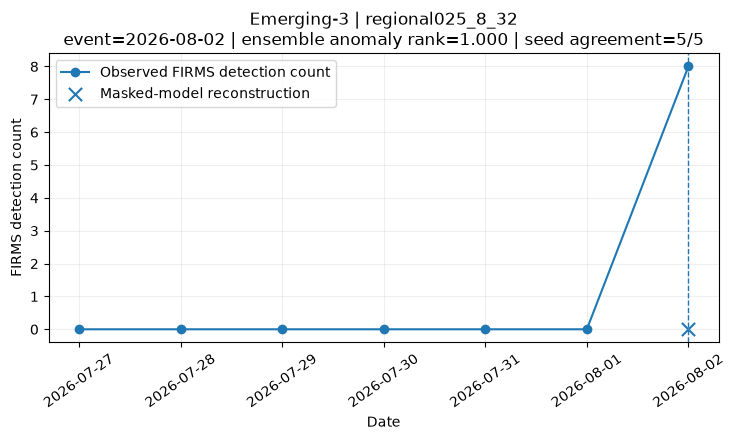

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2\figures\case_Emerging_3_20260802_regional025_8_32.png


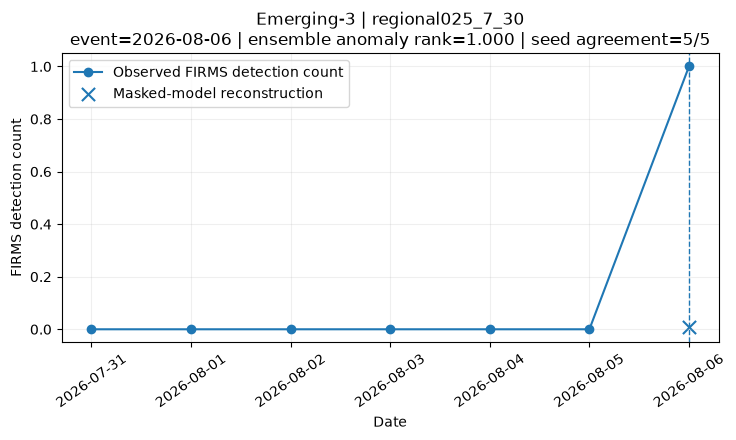

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2\figures\case_Emerging_3_20260806_regional025_7_30.png


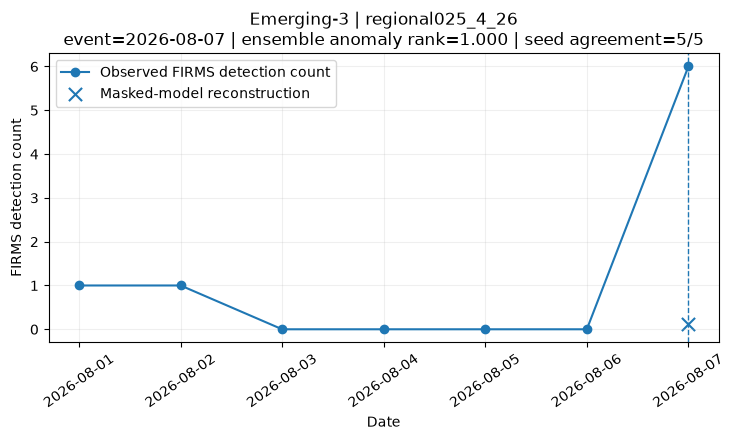

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2\figures\case_Emerging_3_20260807_regional025_4_26.png


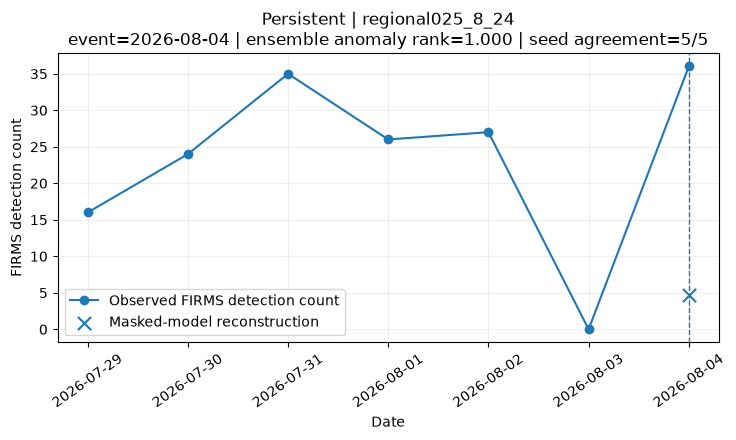

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2\figures\case_Persistent_20260804_regional025_8_24.png


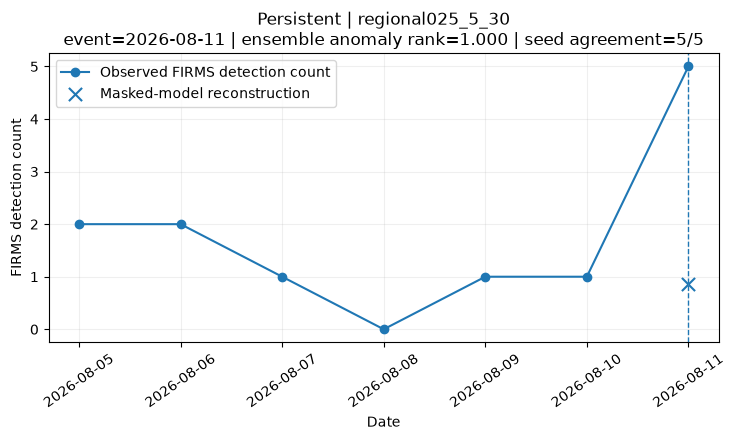

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2\figures\case_Persistent_20260811_regional025_5_30.png


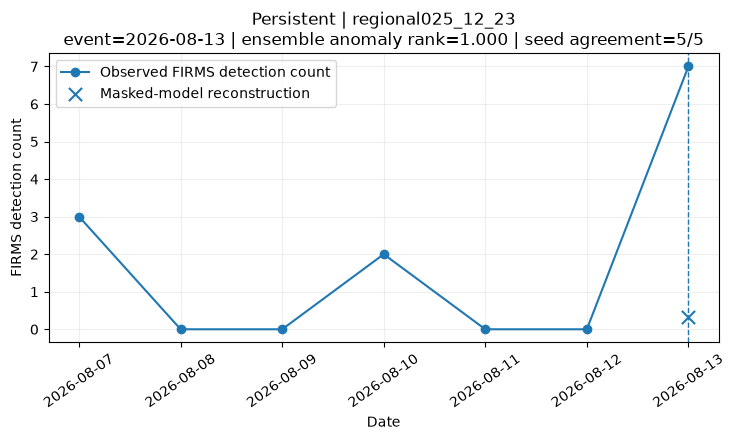

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2\figures\case_Persistent_20260813_regional025_12_23.png


In [25]:
# 14. Create thesis-ready individual case-study plots

for case in case_studies.itertuples(
    index=False
):
    temp = (
        case_context[
            case_context[
                "cell_id"
            ].eq(
                case.cell_id
            )
            &
            case_context[
                "event_date"
            ].eq(
                case.event_date
            )
        ]
        .sort_values(
            "date"
        )
    )

    fig, ax = plt.subplots(
        figsize=(7.5, 4.5)
    )

    ax.plot(
        temp[
            "date"
        ],
        temp[
            "fire_count"
        ],
        marker="o",
        label="Observed FIRMS detection count",
    )

    ax.scatter(
        [
            pd.Timestamp(
                case.event_date
            )
        ],
        [
            case.ensemble_pred_fire_count_approx
        ],
        marker="x",
        s=90,
        label="Masked-model reconstruction",
    )

    ax.axvline(
        pd.Timestamp(
            case.event_date
        ),
        linestyle="--",
        linewidth=1,
    )

    ax.set_xlabel(
        "Date"
    )

    ax.set_ylabel(
        "FIRMS detection count"
    )

    ax.set_title(
        (
            f"{case.research_group} | {case.cell_id}\n"
            f"event={pd.Timestamp(case.event_date).date()} | "
            f"ensemble anomaly rank={case.ensemble_median_rank:.3f} | "
            f"seed agreement={int(case.high_seed_count)}/5"
        )
    )

    ax.grid(
        alpha=0.2
    )

    ax.legend()

    plt.xticks(
        rotation=35
    )

    plt.tight_layout()

    safe_group = (
        str(
            case.research_group
        )
        .replace(
            "-",
            "_",
        )
    )

    safe_date = (
        pd.Timestamp(
            case.event_date
        )
        .strftime(
            "%Y%m%d"
        )
    )

    path = (
        FIGURE_DIR
        / (
            f"case_{safe_group}_"
            f"{safe_date}_"
            f"{case.cell_id}.png"
        )
    )

    plt.savefig(
        path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved:", path)

# PART F — Final spatial concentration table

This is descriptive evidence that the candidate set is not entirely explained by a handful of repeated grid cells.

In [26]:
# 15. Candidate concentration by cell

candidate_cell = (
    candidates
    .groupby(
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
        ]
    )
    .size()
    .rename(
        "candidate_events"
    )
    .reset_index()
    .sort_values(
        "candidate_events",
        ascending=False,
    )
)

top5_share = (
    candidate_cell[
        "candidate_events"
    ]
    .head(5)
    .sum()
    / len(candidates)
)

print(
    "Top-5-cell share:",
    round(
        float(
            top5_share
        ),
        4,
    ),
)

display(
    candidate_cell.head(15)
)

Top-5-cell share: 0.1581


,cell_id,grid_lat,grid_lon,candidate_events
101,regional025_8_24,-2.375,114.125,21
113,regional025_9_23,-2.125,113.875,21
94,regional025_7_28,-2.625,115.125,19
84,regional025_6_28,-2.875,115.125,19
114,regional025_9_24,-2.125,114.125,18
100,regional025_8_23,-2.375,113.875,16
73,regional025_5_28,-3.125,115.125,14
115,regional025_9_25,-2.125,114.375,13
25,regional025_12_24,-1.375,114.125,12
62,regional025_4_27,-3.375,114.875,11


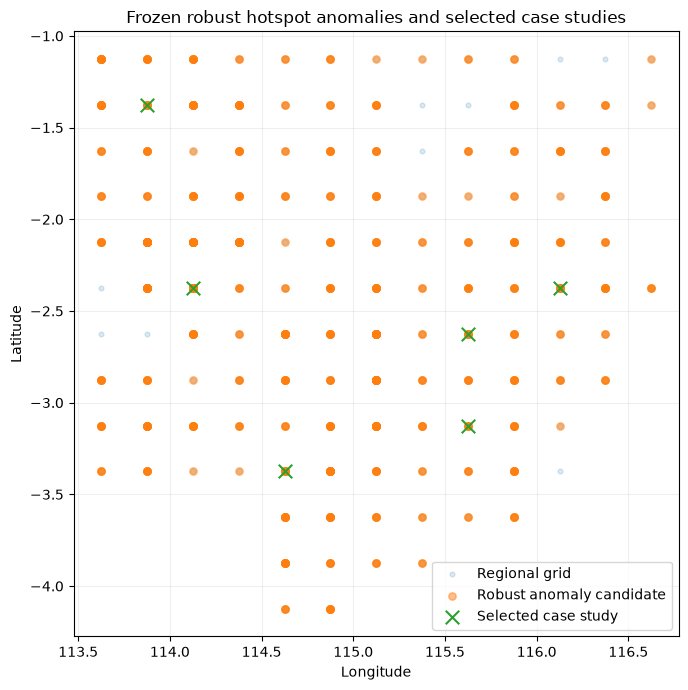

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2\figures\04_final_candidate_map_with_cases.png


In [27]:
# 16. Candidate map for thesis

fig, ax = plt.subplots(
    figsize=(8, 7)
)

all_nodes = (
    raw[
        [
            "cell_id",
            "grid_lon",
            "grid_lat",
        ]
    ]
    .drop_duplicates()
)

ax.scatter(
    all_nodes[
        "grid_lon"
    ],
    all_nodes[
        "grid_lat"
    ],
    s=12,
    alpha=0.16,
    label="Regional grid",
)

ax.scatter(
    candidates[
        "grid_lon"
    ],
    candidates[
        "grid_lat"
    ],
    s=28,
    alpha=0.50,
    label="Robust anomaly candidate",
)

if len(case_studies):
    ax.scatter(
        case_studies[
            "grid_lon"
        ],
        case_studies[
            "grid_lat"
        ],
        s=95,
        marker="x",
        label="Selected case study",
    )

ax.set_xlabel(
    "Longitude"
)

ax.set_ylabel(
    "Latitude"
)

ax.set_title(
    "Frozen robust hotspot anomalies and selected case studies"
)

ax.set_aspect(
    "equal",
    adjustable="box",
)

ax.grid(
    alpha=0.2
)

ax.legend()

plt.tight_layout()

path = (
    FIGURE_DIR
    / "04_final_candidate_map_with_cases.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path)

# PART G — Final thesis-ready result table

This table intentionally separates:

- observed event information;
- model anomaly information;
- post-hoc group information;
- previous hand-crafted history score.

Do not treat `research_group` as a ground-truth anomaly label.

In [28]:
# 17. Thesis-ready selected-case table

thesis_case_table = (
    case_studies[
        case_cols
    ]
    .copy()
)

for col in [
    "ensemble_pred_fire_count_approx",
    "ensemble_pred_frp_sum_approx",
    "ensemble_median_rank",
    "ensemble_rank_iqr",
]:
    if col in thesis_case_table.columns:
        thesis_case_table[
            col
        ] = (
            thesis_case_table[
                col
            ]
            .round(4)
        )

display(
    thesis_case_table
)

,research_group,event_date,cell_id,grid_lat,grid_lon,fire_count,frp_sum,ensemble_pred_fire_count_approx,ensemble_pred_frp_sum_approx,ensemble_median_rank,ensemble_rank_iqr,high_seed_count,history_anomaly_day_rank
0,Emerging-3,2026-08-02,regional025_8_32,-2.375,116.125,8.0,84.98,0.0095,0.0104,1.0,0.0,5,0.785714
1,Emerging-3,2026-08-06,regional025_7_30,-2.625,115.625,1.0,114.58,0.0095,0.0104,1.0,0.0,5,0.819549
2,Emerging-3,2026-08-07,regional025_4_26,-3.375,114.625,6.0,26.73,0.1213,0.2017,1.0,0.0,5,0.593985
3,Persistent,2026-08-04,regional025_8_24,-2.375,114.125,36.0,132.83,4.7149,13.2763,1.0,0.0,5,0.007519
4,Persistent,2026-08-11,regional025_5_30,-3.125,115.625,5.0,243.28,0.8537,1.8452,1.0,0.0,5,0.390977
5,Persistent,2026-08-13,regional025_12_23,-1.375,113.875,7.0,60.44,0.3301,0.6293,1.0,0.0,5,0.533835


In [29]:
# 18. Final summary metrics

summary_metrics = {
    "august_hotspot_cell_days": int(
        len(analysis)
    ),
    "frozen_robust_candidates": int(
        analysis[
            "robust_anomaly_candidate"
        ].sum()
    ),
    "candidate_rate_all_hotspots": float(
        analysis[
            "robust_anomaly_candidate"
        ].mean()
    ),
    "emerging_events": em_n,
    "emerging_candidates": em_c,
    "emerging_candidate_rate": float(
        em_rate
    ),
    "persistent_events": pe_n,
    "persistent_candidates": pe_c,
    "persistent_candidate_rate": float(
        pe_rate
    ),
    "candidate_rate_risk_ratio": float(
        risk_ratio
    ),
    "candidate_rate_risk_ratio_ci95": [
        float(rr_ci_low),
        float(rr_ci_high),
    ],
    "candidate_rate_difference": float(
        risk_difference
    ),
    "candidate_composition_emerging_share": float(
        candidate_emerging_share
    ),
    "baseline_emerging_share": float(
        baseline_emerging_share
    ),
    "candidate_composition_enrichment": float(
        composition_enrichment
    ),
    "top5_cell_candidate_share": float(
        top5_share
    ),
    "interpretation": (
        "Robust anomaly candidate means difficult to reconstruct from preceding "
        "temporal fire context across independently initialized masked models; "
        "it is not an ignition-cause label."
    ),
}

if len(history_summary):
    summary_metrics[
        "history_overlap_jaccard"
    ] = float(
        history_summary[
            "jaccard"
        ].iloc[0]
    )

print(
    json.dumps(
        summary_metrics,
        indent=2,
    )
)

{
  "august_hotspot_cell_days": 2106,
  "frozen_robust_candidates": 620,
  "candidate_rate_all_hotspots": 0.2943969610636277,
  "emerging_events": 217,
  "emerging_candidates": 118,
  "emerging_candidate_rate": 0.543778801843318,
  "persistent_events": 1849,
  "persistent_candidates": 476,
  "persistent_candidate_rate": 0.2574364521362899,
  "candidate_rate_risk_ratio": 2.11228362312667,
  "candidate_rate_risk_ratio_ci95": [
    1.8283053262919557,
    2.4403703475382494
  ],
  "candidate_rate_difference": 0.28634234970702804,
  "candidate_composition_emerging_share": 0.19865319865319866,
  "baseline_emerging_share": 0.10503388189738626,
  "candidate_composition_enrichment": 1.891324923582988,
  "top5_cell_candidate_share": 0.15806451612903225,
  "interpretation": "Robust anomaly candidate means difficult to reconstruct from preceding temporal fire context across independently initialized masked models; it is not an ignition-cause label.",
  "history_overlap_jaccard": 0.100443131462333

In [30]:
# 19. Export final thesis-ready artifacts

group_counts.to_csv(
    EXPORT_DIR
    / "table_candidate_rates_by_group.csv",
    index=False,
)

effect_summary.to_csv(
    EXPORT_DIR
    / "table_candidate_rate_effect_sizes.csv",
    index=False,
)

composition_summary.to_csv(
    EXPORT_DIR
    / "table_candidate_composition_enrichment.csv",
    index=False,
)

case_studies.to_csv(
    EXPORT_DIR
    / "selected_case_studies_full.csv",
    index=False,
)

thesis_case_table.to_csv(
    EXPORT_DIR
    / "table_selected_case_studies.csv",
    index=False,
)

case_context.to_csv(
    EXPORT_DIR
    / "selected_case_temporal_context.csv",
    index=False,
)

candidate_cell.to_csv(
    EXPORT_DIR
    / "candidate_cell_concentration_final.csv",
    index=False,
)

if len(history_summary):
    history_summary.to_csv(
        EXPORT_DIR
        / "table_history_overlap_final.csv",
        index=False,
    )

(
    EXPORT_DIR
    / "final_summary_metrics.json"
).write_text(
    json.dumps(
        summary_metrics,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "Final tables saved to:",
    EXPORT_DIR,
)

print(
    "Final figures saved to:",
    FIGURE_DIR,
)

Final tables saved to: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2\exports
Final figures saved to: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_results_case_studies\t2\figures


# Final interpretation guide

If the outputs reproduce the NB25 pattern, the thesis can state:

1. the frozen multi-seed masked reconstruction rule identifies a stable subset of hotspot cell-days as contextual anomalies;
2. Emerging-3 events are more frequently included in that robust anomaly subset than Persistent events;
3. this relationship is post-hoc validation, not supervised classification;
4. the learned anomaly set overlaps only partially with the previous hand-crafted history anomaly;
5. selected case studies visualize how observed current fire activity can differ sharply from what the temporal context reconstruction suggests.

### Do not write

- “the model detects anthropogenic fires”;
- “the anomaly candidates are intentional burning”;
- “the model proves illegal land clearing”.

Those questions require independent ignition/context evidence.

In [31]:
# 20. Automatic final review

print("=== NB26 FINAL THESIS REVIEW ===")
print()

print(
    f"Emerging-3 candidate rate: "
    f"{em_c}/{em_n} = {em_rate:.3%}"
)

print(
    f"Persistent candidate rate: "
    f"{pe_c}/{pe_n} = {pe_rate:.3%}"
)

print(
    f"Candidate-rate risk ratio: "
    f"{risk_ratio:.3f} "
    f"(95% CI {rr_ci_low:.3f}–{rr_ci_high:.3f})"
)

print(
    f"Candidate-rate difference: "
    f"{risk_difference:.3%}"
)

print(
    f"Emerging share among labeled hotspots: "
    f"{baseline_emerging_share:.3%}"
)

print(
    f"Emerging share among robust candidates: "
    f"{candidate_emerging_share:.3%}"
)

print(
    f"Composition enrichment: "
    f"{composition_enrichment:.3f}x"
)

if len(history_summary):
    print(
        f"History-overlap Jaccard: "
        f"{history_summary['jaccard'].iloc[0]:.4f}"
    )

print(
    f"Top-5-cell candidate share: "
    f"{top5_share:.3%}"
)

print()
print(
    "Selected case studies:",
    len(case_studies),
)

display(
    thesis_case_table
)

print()
print(
    "Model development remains frozen. "
    "The next step is writing/visual presentation or a separately labeled temporal generalization test."
)

=== NB26 FINAL THESIS REVIEW ===

Emerging-3 candidate rate: 118/217 = 54.378%
Persistent candidate rate: 476/1849 = 25.744%
Candidate-rate risk ratio: 2.112 (95% CI 1.828–2.440)
Candidate-rate difference: 28.634%
Emerging share among labeled hotspots: 10.503%
Emerging share among robust candidates: 19.865%
Composition enrichment: 1.891x
History-overlap Jaccard: 0.1004
Top-5-cell candidate share: 15.806%

Selected case studies: 6


,research_group,event_date,cell_id,grid_lat,grid_lon,fire_count,frp_sum,ensemble_pred_fire_count_approx,ensemble_pred_frp_sum_approx,ensemble_median_rank,ensemble_rank_iqr,high_seed_count,history_anomaly_day_rank
0,Emerging-3,2026-08-02,regional025_8_32,-2.375,116.125,8.0,84.98,0.0095,0.0104,1.0,0.0,5,0.785714
1,Emerging-3,2026-08-06,regional025_7_30,-2.625,115.625,1.0,114.58,0.0095,0.0104,1.0,0.0,5,0.819549
2,Emerging-3,2026-08-07,regional025_4_26,-3.375,114.625,6.0,26.73,0.1213,0.2017,1.0,0.0,5,0.593985
3,Persistent,2026-08-04,regional025_8_24,-2.375,114.125,36.0,132.83,4.7149,13.2763,1.0,0.0,5,0.007519
4,Persistent,2026-08-11,regional025_5_30,-3.125,115.625,5.0,243.28,0.8537,1.8452,1.0,0.0,5,0.390977
5,Persistent,2026-08-13,regional025_12_23,-1.375,113.875,7.0,60.44,0.3301,0.6293,1.0,0.0,5,0.533835



Model development remains frozen. The next step is writing/visual presentation or a separately labeled temporal generalization test.
